# 02 - Feature engineering, model development and MLflow tracking

In [1]:
%pip install joblib scikit-learn pandas


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import json
from src.heart.train import run_training
meta = run_training(use_mlflow=False)   # set use_mlflow=True to log to ./mlruns
print('selected:', meta['selected_model'])

selected: logistic_regression


In [3]:
import pandas as pd
pd.DataFrame(meta['all_results']).T[['cv_accuracy','cv_precision','cv_recall','cv_roc_auc','test_accuracy','test_recall','test_roc_auc']].round(3)

,cv_accuracy,cv_precision,cv_recall,cv_roc_auc,test_accuracy,test_recall,test_roc_auc
logistic_regression,0.830527,0.859379,0.765217,0.898108,0.885246,0.928571,0.965368
random_forest,0.817857,0.830322,0.764427,0.896852,0.836066,0.857143,0.94697


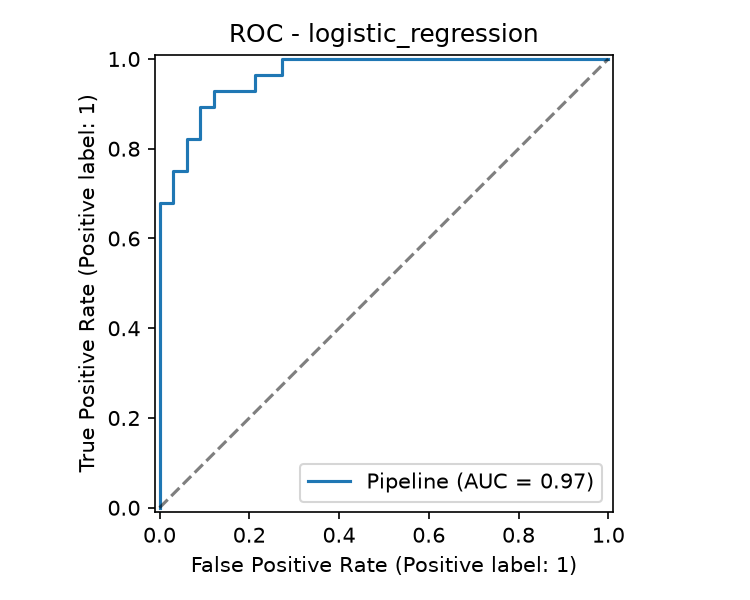

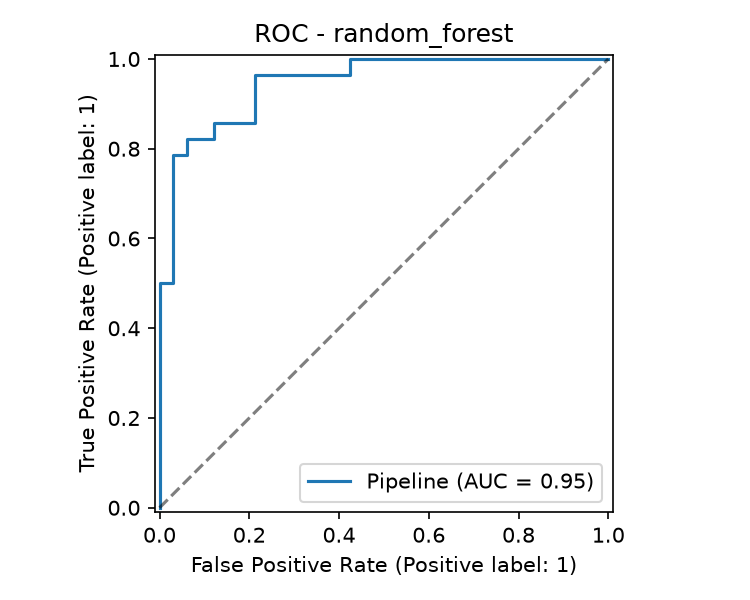

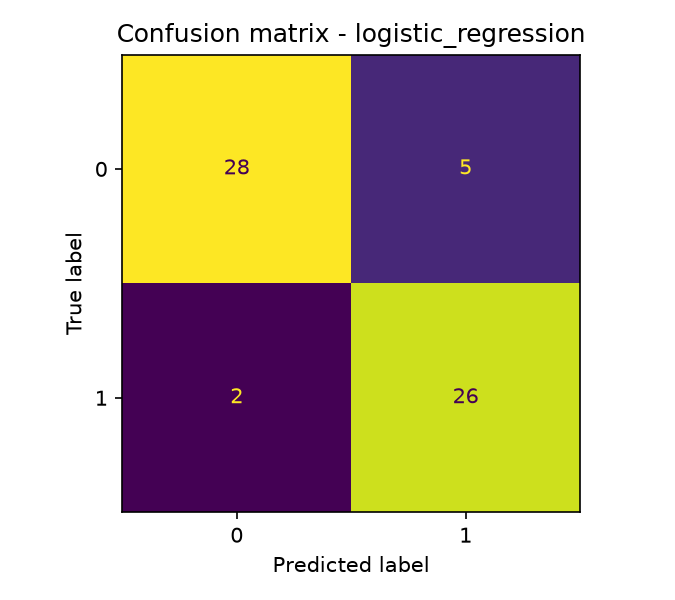

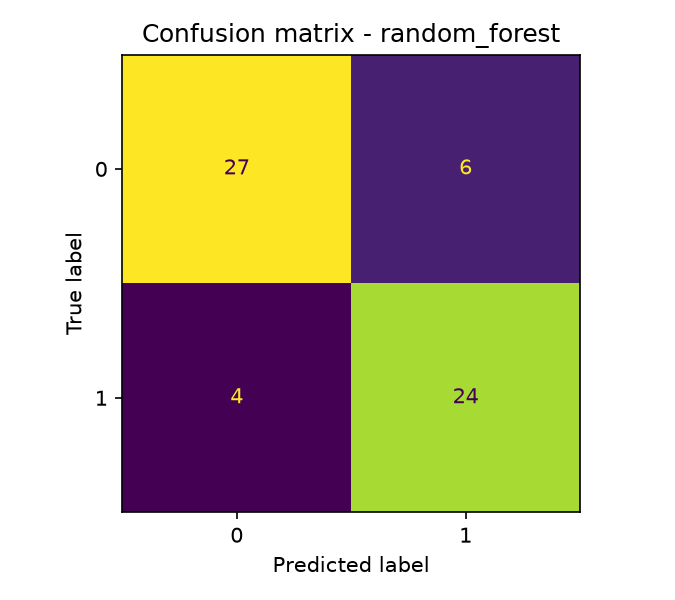

In [4]:
from IPython.display import Image, display
for f in ['roc_logistic_regression','roc_random_forest','cm_logistic_regression','cm_random_forest']:
    display(Image(str(ROOT / 'reports' / 'figures' / f'{f}.png'), width=380))

Pipeline = `ColumnTransformer` (median-impute + scale numerics; mode-impute + one-hot categoricals) -> estimator, tuned by `GridSearchCV` inside 5-fold stratified CV (nested). Selection rule: best mean CV ROC-AUC. For tracked runs use `python -m src.heart.train` then `mlflow ui`.